# Waze: User Churn Data (Visualization Stage)

Case study from the Google Advanced Data Analytics Professional Certificate. Building on the Plan/Analyze stage, this notebook explores distributions of driving behavior and their relationship to churn, ahead of sharing findings with Waze's Director of Data Analysis.

## Plan


### Imports and data loading





In [48]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

In [49]:
# Load the dataset into a dataframe
df = pd.read_csv('waze_dataset.csv')

## Analyze


none of the columns need to be chnaged format. there are 700 rows missing in the "label" column.

### Data exploration and cleaning

Which columns are most applicable, which can be eliminated, and how should missing data and outliers be handled?







Label, sessions, drives, total_Sessions, n_days_after_onboarding, driven_km_drives, duration_minutes_drives, activity_days, driving_days and device.
The ID is unnecessary there is the index, and the total navigations favs 1&2 is not really important for what we need but I think keeping it is not bad either.
You can know the missing data using info() then if u wanna see them u can mask and get them. For our case 700 labels is a big number missing, so 
Using describe() we can check for outliers or the upper and lower using interquantile. If they are actually valid we keep them if not remove them simple.

In [50]:
df.head(7)

,ID,label,sessions,drives,total_sessions,n_days_after_onboarding,total_navigations_fav1,total_navigations_fav2,driven_km_drives,duration_minutes_drives,activity_days,driving_days,device
0,0,retained,283,226,296.748273,2276,208,0,2628.845068,1985.775061,28,19,Android
1,1,retained,133,107,326.896596,1225,19,64,13715.920550,3160.472914,13,11,iPhone
2,2,retained,114,95,135.522926,2651,0,0,3059.148818,1610.735904,14,8,Android
3,3,retained,49,40,67.589221,15,322,7,913.591123,587.196542,7,3,iPhone
4,4,retained,84,68,168.247020,1562,166,5,3950.202008,1219.555924,27,18,Android
5,5,retained,113,103,279.544437,2637,0,0,901.238699,439.101397,15,11,iPhone
6,6,retained,3,2,236.725314,360,185,18,5249.172828,726.577205,28,23,iPhone


In [51]:
df.size

194987

In [52]:
df.describe()

,ID,sessions,drives,total_sessions,n_days_after_onboarding,total_navigations_fav1,total_navigations_fav2,driven_km_drives,duration_minutes_drives,activity_days,driving_days
count,14999.000000,14999.000000,14999.000000,14999.000000,14999.000000,14999.000000,14999.000000,14999.000000,14999.000000,14999.000000,14999.000000
mean,7499.000000,80.633776,67.281152,189.964447,1749.837789,121.605974,29.672512,4039.340921,1860.976012,15.537102,12.179879
std,4329.982679,80.699065,65.913872,136.405128,1008.513876,148.121544,45.394651,2502.149334,1446.702288,9.004655,7.824036
min,0.000000,0.000000,0.000000,0.220211,4.000000,0.000000,0.000000,60.441250,18.282082,0.000000,0.000000
25%,3749.500000,23.000000,20.000000,90.661156,878.000000,9.000000,0.000000,2212.600607,835.996260,8.000000,5.000000
50%,7499.000000,56.000000,48.000000,159.568115,1741.000000,71.000000,9.000000,3493.858085,1478.249859,16.000000,12.000000
75%,11248.500000,112.000000,93.000000,254.192341,2623.500000,178.000000,43.000000,5289.861262,2464.362632,23.000000,19.000000
max,14998.000000,743.000000,596.000000,1216.154633,3500.000000,1236.000000,415.000000,21183.401890,15851.727160,31.000000,30.000000


In [53]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 14999 entries, 0 to 14998
Data columns (total 13 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   ID                       14999 non-null  int64  
 1   label                    14299 non-null  object 
 2   sessions                 14999 non-null  int64  
 3   drives                   14999 non-null  int64  
 4   total_sessions           14999 non-null  float64
 5   n_days_after_onboarding  14999 non-null  int64  
 6   total_navigations_fav1   14999 non-null  int64  
 7   total_navigations_fav2   14999 non-null  int64  
 8   driven_km_drives         14999 non-null  float64
 9   duration_minutes_drives  14999 non-null  float64
 10  activity_days            14999 non-null  int64  
 11  driving_days             14999 non-null  int64  
 12  device                   14999 non-null  object 
dtypes: float64(3), int64(8), object(2)
memory usage: 1.5+ MB


## Construct

### Identifying and handling outliers


Using describe() we can check for outliers or the upper and lower using interquantile. If they are actually valid we keep them if not remove them simple.

### Select visualization types

Which chart types make the most sense for EDA on this dataset?



Bar chart, Boxplot, Histogram, and Scatterplot.

### Visualizations

Examine the spread and distribution of key variables using box plots and histograms.

#### **`sessions`**

_The number of occurrence of a user opening the app during the month_

Text(0.5, 1.0, 'Sessions Boxplot')

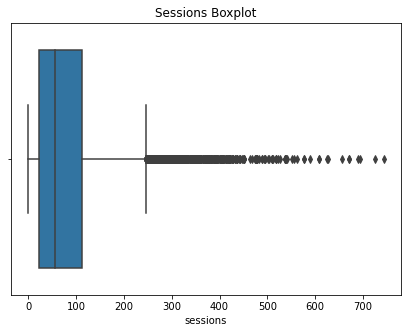

In [54]:
# Box plot
plt.figure(figsize=(7,5))
sns.boxplot(df["sessions"])
plt.title("Sessions Boxplot")


Text(0.5, 1.0, 'Sessions Count')

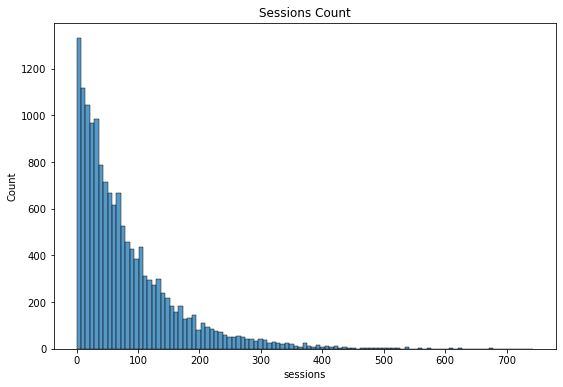

In [55]:
# Histogram
plt.figure(figsize=(9,6))
sns.histplot(df["sessions"])
plt.title("Sessions Count")

The `sessions` variable is a right-skewed distribution with half of the observations having 56 or fewer sessions. However, as indicated by the boxplot, some users have more than 700.

#### **`drives`**

_An occurrence of driving at least 1 km during the month_

Text(0.5, 1.0, 'occurrence of driving at least 1 km during the month')

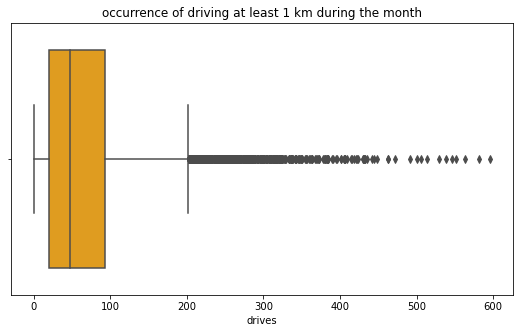

In [56]:
# Box plot
plt.figure(figsize=(9,5))
sns.boxplot(df["drives"], color="orange")
plt.title("occurrence of driving at least 1 km during the month")


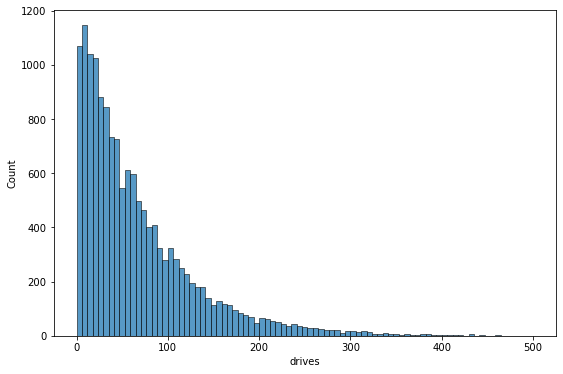

In [57]:
# Histogram
plt.figure(figsize=(9,6))
sns.histplot(df["drives"], binrange=(0,500))

The `drives` information follows a distribution similar to the `sessions` variable. It is right-skewed, approximately log-normal, with a median of 48. However, some drivers had over 400 drives in the last month.

#### **`total_sessions`**

_A model estimate of the total number of sessions since a user has onboarded_

Text(0.5, 1.0, 'total number of sessions since a user has onboarded')

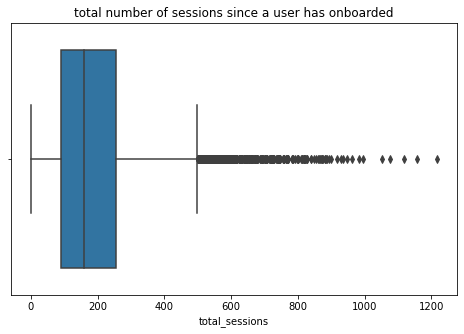

In [58]:
# Box plot
plt.figure(figsize=(8,5))
sns.boxplot(df["total_sessions"])
plt.title("total number of sessions since a user has onboarded")


Text(0.5, 1.0, 'total number of sessions since a user has onboarded')

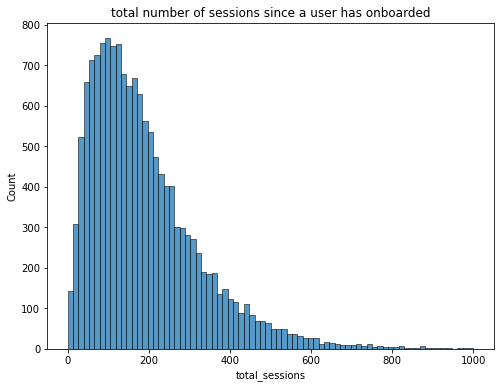

In [59]:
# Histogram
plt.figure(figsize=(8,6))
sns.histplot(df["total_sessions"], binrange=(0,1000))
plt.title("total number of sessions since a user has onboarded")

The `total_sessions` is a right-skewed distribution. The median total number of sessions is 159.6. This is interesting information because, if the median number of sessions in the last month was 48 and the median total sessions was ~160, then it seems that a large proportion of a user's total drives might have taken place in the last month. This is something you can examine more closely later.

#### **`n_days_after_onboarding`**

_The number of days since a user signed up for the app_

Text(0.5, 1.0, 'Number of days since a user signed up for the app')

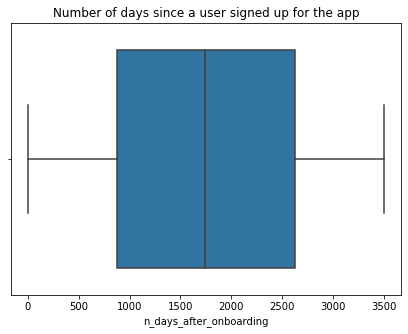

In [60]:
# Box plot
plt.figure(figsize=(7,5))
sns.boxplot(df["n_days_after_onboarding"])
plt.title("Number of days since a user signed up for the app")

Text(0.5, 1.0, 'Number of days since a user signed up for the app')

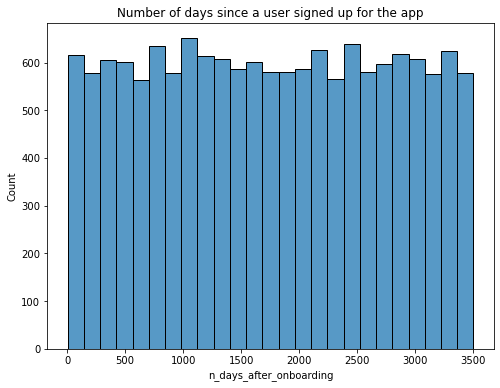

In [61]:
# Histogram
plt.figure(figsize=(8,6))
sns.histplot(df["n_days_after_onboarding"])
plt.title("Number of days since a user signed up for the app")

The total user tenure (i.e., number of days since
onboarding) is a uniform distribution with values ranging from near-zero to \~3,500 (\~9.5 years).

#### **`driven_km_drives`**

_Total kilometers driven during the month_

Text(0.5, 1.0, 'Total kilometers driven during the month')

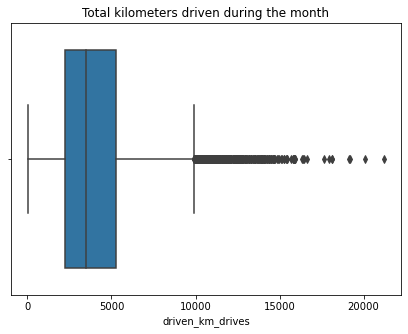

In [62]:
# Box plot
plt.figure(figsize=(7,5))
sns.boxplot(df["driven_km_drives"])
plt.title("Total kilometers driven during the month")

Text(0.5, 1.0, 'Total kilometers driven during the month')

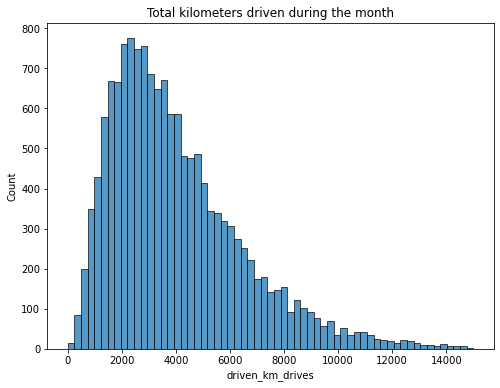

In [63]:
# Histogram
plt.figure(figsize=(8,6))
sns.histplot(df["driven_km_drives"], binrange=(0,15000))
plt.title("Total kilometers driven during the month")

The number of drives driven in the last month per user is a right-skewed distribution with half the users driving under 3,495 kilometers. As you discovered in the analysis from the previous course, the users in this dataset drive _a lot_. The longest distance driven in the month was over half the circumferene of the earth.

#### **`duration_minutes_drives`**

_Total duration driven in minutes during the month_

Text(0.5, 1.0, 'Total duration driven in minutes during the month')

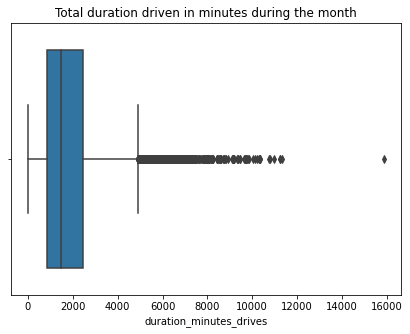

In [64]:
# Box plot
plt.figure(figsize=(7,5))
sns.boxplot(df["duration_minutes_drives"])
plt.title("Total duration driven in minutes during the month")

Text(0.5, 1.0, 'Total duration driven in minutes during the month')

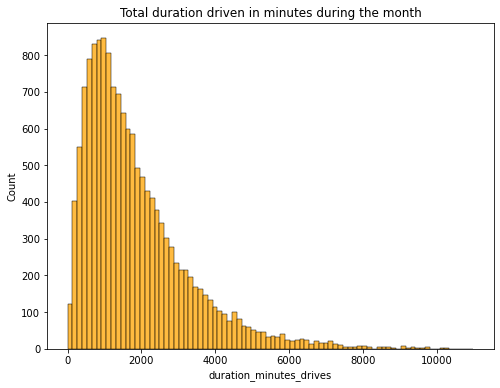

In [65]:
# Histogram
plt.figure(figsize=(8,6))
sns.histplot(df["duration_minutes_drives"], binrange=(0,11000), color="orange")
plt.title("Total duration driven in minutes during the month")

The `duration_minutes_drives` variable has a heavily skewed right tail. Half of the users drove less than \~1,478 minutes (\~25 hours), but some users clocked over 250 hours over the month.

#### **`activity_days`**

_Number of days the user opens the app during the month_

Text(0.5, 1.0, 'Number of days the user opens the app during the month')

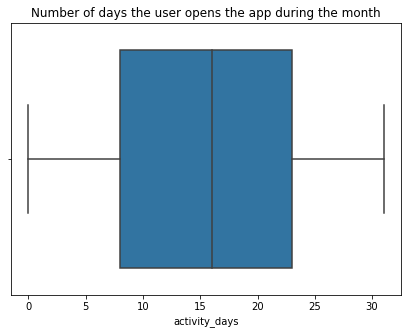

In [66]:
# Box plot
plt.figure(figsize=(7,5))
sns.boxplot(df["activity_days"])
plt.title("Number of days the user opens the app during the month")

Text(0.5, 1.0, 'Number of days the user opens the app during the month')

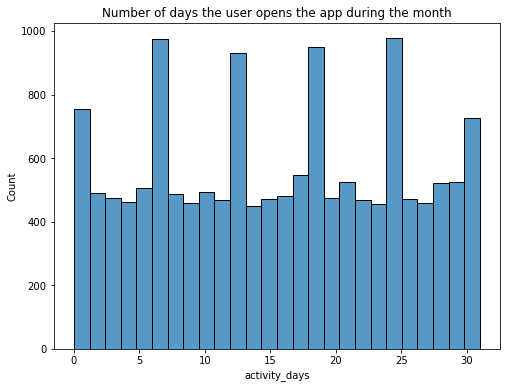

In [67]:
# Histogram
plt.figure(figsize=(8,6))
sns.histplot(df["activity_days"])
plt.title("Number of days the user opens the app during the month")

Within the last month, users opened the app a median of 16 times. The box plot reveals a centered distribution. The histogram shows a nearly uniform distribution of ~500 people opening the app on each count of days. However, there are ~250 people who didn't open the app at all and ~250 people who opened the app every day of the month.

This distribution is noteworthy because it does not mirror the `sessions` distribution, which you might think would be closely correlated with `activity_days`.

#### **`driving_days`**

_Number of days the user drives (at least 1 km) during the month_

Text(0.5, 1.0, 'Number of days the user drives (at least 1 km) during the month')

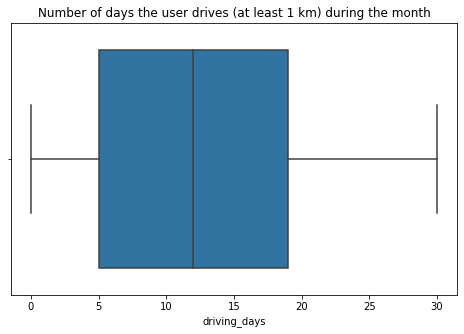

In [68]:
# Box plot
plt.figure(figsize=(8,5))
sns.boxplot(df["driving_days"])
plt.title("Number of days the user drives (at least 1 km) during the month")

Text(0.5, 1.0, 'Number of days the user drives (at least 1 km) during the month')

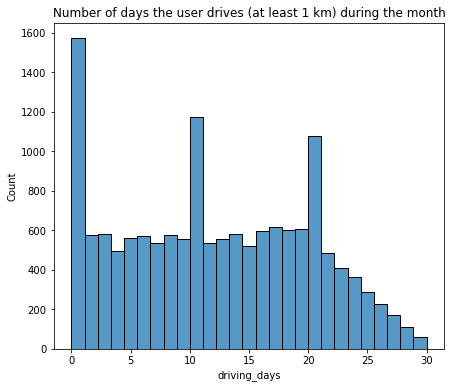

In [69]:
# Histogram
plt.figure(figsize=(7,6))
sns.histplot(df["driving_days"])
plt.title("Number of days the user drives (at least 1 km) during the month")

The number of days users drove each month is almost uniform, and it largely correlates with the number of days they opened the app that month, except the `driving_days` distribution tails off on the right.

However, there were almost twice as many users (\~1,000 vs. \~550) who did not drive at all during the month. This might seem counterintuitive when considered together with the information from `activity_days`. That variable had \~500 users opening the app on each of most of the day counts, but there were only \~250 users who did not open the app at all during the month and ~250 users who opened the app every day. Flag this for further investigation later.

#### **`device`**

_The type of device a user starts a session with_

This is a categorical variable, so you do not plot a box plot for it. A good plot for a binary categorical variable is a pie chart.

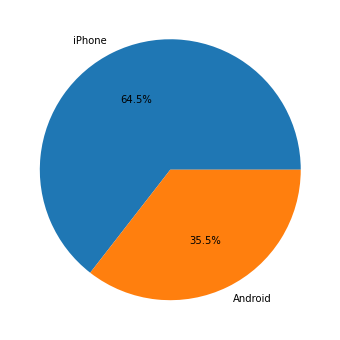

In [70]:
# Pie chart
plt.figure(figsize=(6,6))
devices = df["device"].value_counts().reset_index()
devices.columns = ["device", "counts"]
plt.pie(devices["counts"], labels = devices["device"], autopct="%1.1f%%");


There are nearly twice as many iPhone users as Android users represented in this data.

#### **`label`**

_Binary target variable (“retained” vs “churned”) for if a user has churned anytime during the course of the month_

This is also a categorical variable, and as such would not be plotted as a box plot. Plot a pie chart instead.

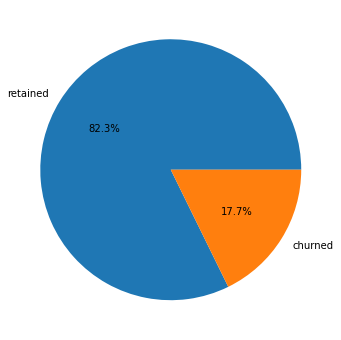

In [71]:
# Pie chart
labels = df["label"].value_counts()
labels
plt.figure(figsize=(6,6))
plt.pie(labels, labels =labels.index, autopct="%1.1f%%");

Less than 18% of the users churned.

#### **`driving_days` vs. `activity_days`**

Because both `driving_days` and `activity_days` represent counts of days over a month and they're also closely related, you can plot them together on a single histogram. This will help to better understand how they relate to each other without having to scroll back and forth comparing histograms in two different places.

Plot a histogram that, for each day, has a bar representing the counts of `driving_days` and `activity_days`.

Text(0.5, 1.0, 'counts of driving days and activity days')

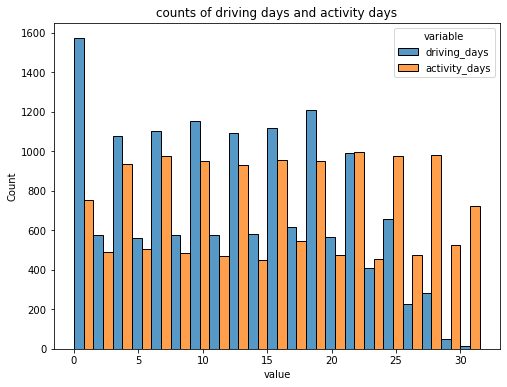

In [72]:
# Histogram
driving_activity = pd.melt(df,value_vars=["driving_days","activity_days"])
plt.figure(figsize=(8,6))
sns.histplot(driving_activity, x="value" ,hue="variable", multiple="dodge", binwidth =1.5);
plt.title("counts of driving days and activity days")

As observed previously, this might seem counterintuitive. After all, why are there _fewer_ people who didn't use the app at all during the month and _more_ people who didn't drive at all during the month?

On the other hand, it could just be illustrative of the fact that, while these variables are related to each other, they're not the same. People probably just open the app more than they use the app to drive&mdash;perhaps to check drive times or route information, to update settings, or even just by mistake.

Nonetheless, it might be worthwile to contact the data team at Waze to get more information about this, especially because it seems that the number of days in the month is not the same between variables.

Confirm the maximum number of days for each variable&mdash;`driving_days` and `activity_days`.

In [73]:
print("max driving days: ", df["driving_days"].max())
print("max activity days: ", df["activity_days"].max())

max driving days:  30
max activity days:  31


It's true. Although it's possible that not a single user drove all 31 days of the month, it's highly unlikely, considering there are 15,000 people represented in the dataset.

One other way to check the validity of these variables is to plot a simple scatter plot with the x-axis representing one variable and the y-axis representing the other.

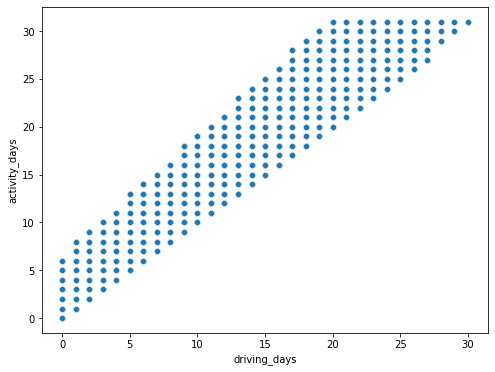

In [74]:
# Scatter plot
plt.figure(figsize=(8,6))
sns.scatterplot(x=df["driving_days"], y=df["activity_days"]);

Notice that there is a theoretical limit. If you use the app to drive, then by definition it must count as a day-use as well. In other words, you cannot have more drive-days than activity-days. None of the samples in this data violate this rule, which is good.

#### **Retention by device**


Text(0.5, 1.0, 'User labels by Device')

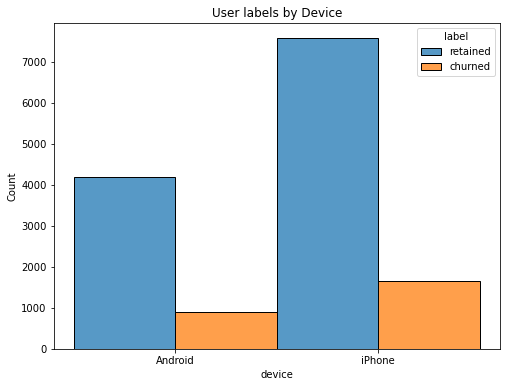

In [75]:
# Histogram
plt.figure(figsize=(8,6))
sns.histplot(x=df["device"], hue=df["label"], multiple="dodge")
plt.title("User labels by Device")

The proportion of churned users to retained users is consistent between device types.

#### **Retention by kilometers driven per driving day**



In [76]:
# 1. Create `km_per_driving_day` column
df["km_per_driving_day"] = df["driven_km_drives"] / df["driving_days"]

# 2. Call `describe()` on the new column
df["km_per_driving_day"].describe()

count    1.499900e+04
mean              inf
std               NaN
min      3.022063e+00
25%      1.672804e+02
50%      3.231459e+02
75%      7.579257e+02
max               inf
Name: km_per_driving_day, dtype: float64

The mean value is infinity, the standard deviation is NaN, and the max value is infinity.

This is the result of there being values of zero in the `driving_days` column. Pandas imputes a value of infinity in the corresponding rows of the new column because division by zero is undefined.

In [77]:
# 1. Convert infinite values to zero
df["km_per_driving_day"] = df["km_per_driving_day"].replace(np.inf, 0)

# 2. Confirm that it worked
df["km_per_driving_day"].describe()

count    14999.000000
mean       578.963113
std       1030.094384
min          0.000000
25%        136.238895
50%        272.889272
75%        558.686918
max      15420.234110
Name: km_per_driving_day, dtype: float64

The maximum value is 15,420 kilometers _per drive day_. This is physically impossible. Driving 100 km/hour for 12 hours is 1,200 km. It's unlikely many people averaged more than this each day they drove, so, for now, disregard rows where the distance in this column is greater than 1,200 km.

Plot a histogram of the new `km_per_driving_day` column, disregarding those users with values greater than 1,200 km. Each bar should be the same length and have two colors, one color representing the percent of the users in that bar that churned and the other representing the percent that were retained. This can be done by setting the `multiple` parameter of seaborn's [`histplot()`](https://seaborn.pydata.org/generated/seaborn.histplot.html) function to `fill`.

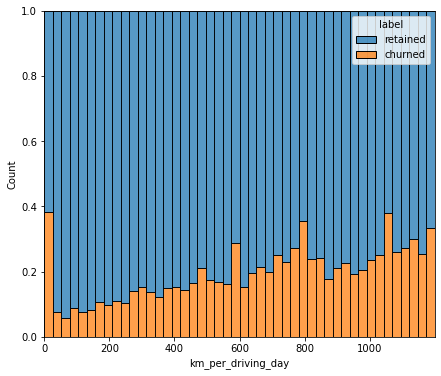

In [93]:
# Histogram
df1200 = df[df["km_per_driving_day"] < 1200]
plt.figure(figsize=(7,6))
sns.histplot(df1200, x="km_per_driving_day", hue="label", multiple="fill");

The churn rate tends to increase as the mean daily distance driven increases, confirming what was found in the previous course. It would be worth investigating further the reasons for long-distance users to discontinue using the app.

#### **Churn rate per number of driving days**

Create another histogram just like the previous one, only this time it should represent the churn rate for each number of driving days.

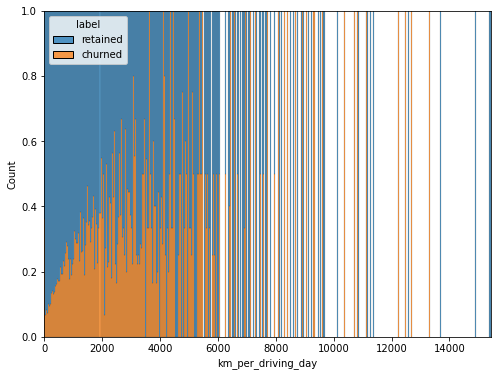

In [103]:
# Histogram
plt.figure(figsize=(8,6))
sns.histplot(x=df["km_per_driving_day"], hue=df["label"], multiple="fill");

The churn rate is highest for people who didn't use Waze much during the last month. The more times they used the app, the less likely they were to churn. While 40% of the users who didn't use the app at all last month churned, nobody who used the app 30 days churned.

This isn't surprising. If people who used the app a lot churned, it would likely indicate dissatisfaction. When people who don't use the app churn, it might be the result of dissatisfaction in the past, or it might be indicative of a lesser need for a navigational app. Maybe they moved to a city with good public transportation and don't need to drive anymore.

#### **Proportion of sessions that occurred in the last month**


In [104]:
df["percent_sessions_in_last_month"] = df["sessions"] / df["total_sessions"] * 100
df["percent_sessions_in_last_month"]

0        95.367025
1        40.685648
2        84.118609
3        72.496767
4        49.926590
           ...    
14994    28.863413
14995    22.379672
14996    64.689300
14997    82.537418
14998    20.655323
Name: percent_sessions_in_last_month, Length: 14999, dtype: float64

What is the median value of the new column?

In [105]:
df["percent_sessions_in_last_month"].median()

42.30970299276318

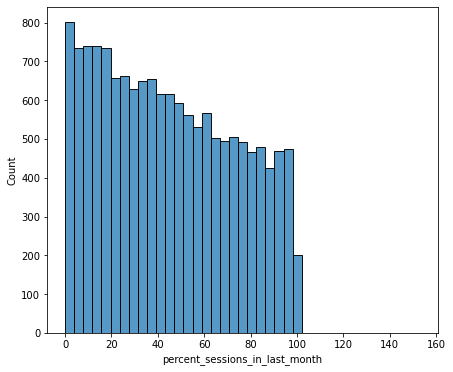

In [108]:
# Histogram
plt.figure(figsize=(7,6))
sns.histplot(df["percent_sessions_in_last_month"])

Check the median value of the `n_days_after_onboarding` variable.

In [109]:
df["n_days_after_onboarding"].median()

1741.0

Half of the people in the dataset had 40% or more of their sessions in just the last month, yet the overall median time since onboarding is almost five years.

Make a histogram of `n_days_after_onboarding` for just the people who had 40% or more of their total sessions in the last month.

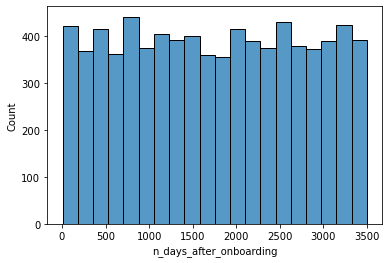

In [112]:
# Histogram
df40 = df[df["percent_sessions_in_last_month"] >= 40]
sns.histplot(df40["n_days_after_onboarding"])

The number of days since onboarding for users with 40% or more of their total sessions occurring in just the last month is a uniform distribution. This is very strange. It's worth asking Waze why so many long-time users suddenly used the app so much in the last month.

### Handling outliers

The box plots above show several variables with outliers that don't look like data entry errors, more likely just heavy users. Cap them at the 95th percentile rather than dropping them.



In [113]:
def quant(df, column):
    return df[column].quantile(0.95)

In [114]:
columns = ["sessions" ,"drives","total_sessions","driven_km_drives" ,"duration_minutes_drives"]
for column in columns :
    th95 = quant(df, column)
    df.loc[df[column] > th95, column] = th95

In [115]:
df.describe()

,ID,sessions,drives,total_sessions,n_days_after_onboarding,total_navigations_fav1,total_navigations_fav2,driven_km_drives,duration_minutes_drives,activity_days,driving_days,km_per_driving_day,percent_sessions_in_last_month
count,14999.000000,14999.000000,14999.000000,14999.000000,14999.000000,14999.000000,14999.000000,14999.000000,14999.000000,14999.000000,14999.000000,14999.000000,14999.000000
mean,7499.000000,76.568705,64.058204,184.031320,1749.837789,121.605974,29.672512,3939.632764,1789.647426,15.537102,12.179879,578.963113,44.925534
std,4329.982679,67.297958,55.306924,118.600463,1008.513876,148.121544,45.394651,2216.041510,1222.705167,9.004655,7.824036,1030.094384,28.691863
min,0.000000,0.000000,0.000000,0.220211,4.000000,0.000000,0.000000,60.441250,18.282082,0.000000,0.000000,0.000000,0.000000
25%,3749.500000,23.000000,20.000000,90.661156,878.000000,9.000000,0.000000,2212.600607,835.996260,8.000000,5.000000,136.238895,19.622145
50%,7499.000000,56.000000,48.000000,159.568115,1741.000000,71.000000,9.000000,3493.858085,1478.249859,16.000000,12.000000,272.889272,42.309703
75%,11248.500000,112.000000,93.000000,254.192341,2623.500000,178.000000,43.000000,5289.861262,2464.362632,23.000000,19.000000,558.686918,68.721626
max,14998.000000,243.000000,201.000000,454.363204,3500.000000,1236.000000,415.000000,8889.794236,4668.899349,31.000000,30.000000,15420.234110,153.063707


#### **Conclusion**

Analysis revealed that the overall churn rate is \~17%, and that this rate is consistent between iPhone users and Android users.

Perhaps you feel that the more deeply you explore the data, the more questions arise. This is not uncommon! In this case, it's worth asking the Waze data team why so many users used the app so much in just the last month.

Also, EDA has revealed that users who drive very long distances on their driving days are _more_ likely to churn, but users who drive more often are _less_ likely to churn. The reason for this discrepancy is an opportunity for further investigation, and it would be something else to ask the Waze data team about.

## Execute


### Results and evaluation

What did the visualizations reveal about the dataset, and what further questions did they raise?

### Conclusion



Most of them are right skewed like sessions, drives, driven_km_drives, its not normal distribution most values are low and a few are very high.
Yeah the km_per_driving_day had infinite values cuz some users had 0 driving_days, and the max was like 15,420 km per day which is impossible so thats erroneous.
Yeah like why users who drive long distance churn more but users who drive more often churn less, doesnt make sense together, worth asking the team.
Around 17% churned, 83% retained.
km_per_driving_day and driving_days, the more distance they drive per day the more likely to churn, but the more days they use the app the less likely to churn. Device type didnt matter tho, churn rate same for iPhone and Android.
No actually, half the users had 40%+ of sessions in the last month but the median onboarding time was almost 5 years, so its long time users being active recently not new users.

